In [1]:
import sys; sys.path.append("..")
import numpy as np
from torch.utils.data import DataLoader
from src.dataset import CamVidDataset
from src.transforms import make_transform

d = "../data"
tf = make_transform(256)
train_ds = CamVidDataset(f"{d}/train", f"{d}/trainannot", tf)
val_ds = CamVidDataset(f"{d}/val", f"{d}/valannot", tf)
print(len(train_ds), len(val_ds))

train_dl = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)
val_dl = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=0)
x, y = next(iter(train_dl))
print(x.shape, y.shape, y.dtype)

vals = set()
for i in range(len(train_ds)):
    vals |= set(np.unique(train_ds[i][1].numpy()).tolist())
print(sorted(vals))

367 101
torch.Size([8, 3, 256, 256]) torch.Size([8, 256, 256]) torch.int64
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


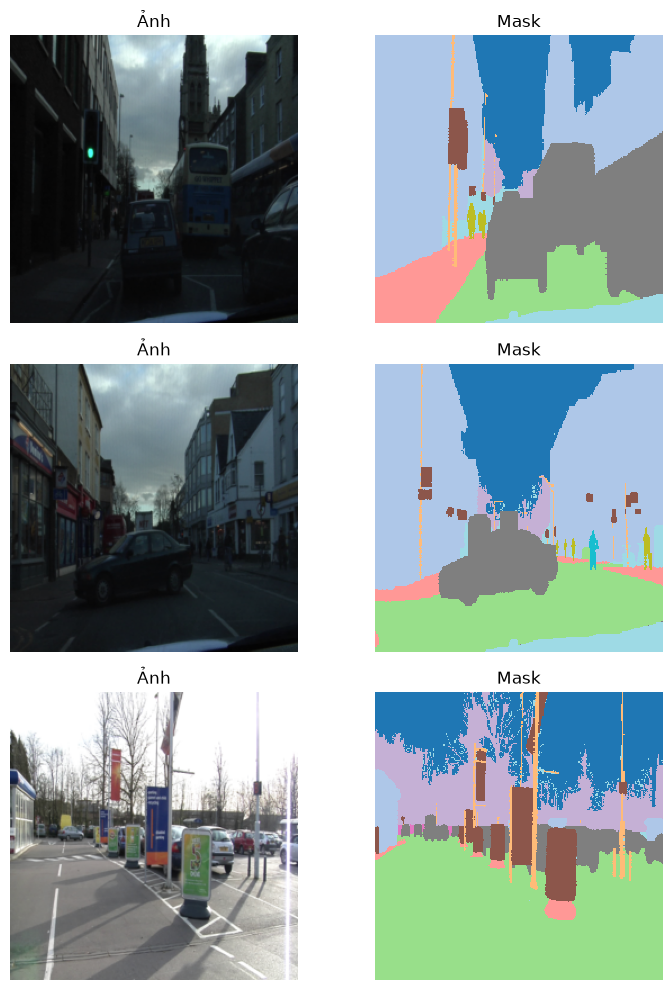

In [2]:
import matplotlib.pyplot as plt
from src.transforms import MEAN, STD

fig, ax = plt.subplots(3, 2, figsize=(8, 10))
for k in range(3):
    img, m = train_ds[k * 50]
    im = (img * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()
    ax[k, 0].imshow(im); ax[k, 0].set_title("Ảnh"); ax[k, 0].axis("off")
    ax[k, 1].imshow(m, cmap="tab20", vmin=0, vmax=11, interpolation="nearest")
    ax[k, 1].set_title("Mask"); ax[k, 1].axis("off")
plt.tight_layout()
plt.savefig("../report/mau_anh_mask.png", dpi=150)
plt.show()